In [4]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score , mean_absolute_error, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split, RandomizedSearchCV
from category_encoders import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline, make_pipeline
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVR
import seaborn as sns
import pandas as pd
import numpy as np
import pickle

from sklearn.feature_selection import mutual_info_regression

In [5]:
df = pd.read_csv(r"C:\Users\SART\Desktop\Practise\csvs\Pakwheel Data.csv")
df.head()


,Unnamed: 0,Title,Model,CC,Engine_type,Transmission,Km_Driven,prices
0,0,Honda Vezel 2019 Hybrid Z Honda Sensing for ...,2019,1500 cc,Petrol,Automatic,"26,755 km",72.50
1,1,Suzuki Wagon R 2020 Hybrid FX for Sale,2020,660 cc,Hybrid,Automatic,"9,744 km",32.50
2,2,Toyota Corolla Axio 2008 G Kurashiko for Sale,2008,1500 cc,Petrol,Automatic,"85,000 km",29.80
3,3,Toyota Corolla 2018 XLi VVTi for Sale,2018,1300 cc,Petrol,Manual,"40,000 km",33.25
4,4,Daihatsu Mira 2020 G SA III for Sale,2020,660 cc,Petrol,Automatic,"23,300 km",35.75


In [6]:
df.shape

(60555, 8)

In [7]:
df.drop(columns = 'Unnamed: 0', inplace = True)

In [8]:
df['Title'].nunique()

8327

In [9]:
df['Title'][:5]

0    Honda Vezel  2019 Hybrid Z Honda Sensing  for ...
1              Suzuki Wagon R  2020 Hybrid FX for Sale
2       Toyota Corolla Axio  2008 G Kurashiko for Sale
3               Toyota Corolla  2018 XLi VVTi for Sale
4                Daihatsu Mira  2020 G SA III for Sale
Name: Title, dtype: str

<h1>Data Cleaning<h1/>

In [10]:
df['CarName'] = df['Title'].str.split('\d{4}').str[0].str.strip()

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\SART\AppData\Local\Temp\ipykernel_22728\2034751572.py:1: SyntaxWarning: invalid escape sequence '\d'
  df['CarName'] = df['Title'].str.split('\d{4}').str[0].str.strip()


In [11]:
df.head()

,Title,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,Honda Vezel 2019 Hybrid Z Honda Sensing for ...,2019,1500 cc,Petrol,Automatic,"26,755 km",72.50,Honda Vezel
1,Suzuki Wagon R 2020 Hybrid FX for Sale,2020,660 cc,Hybrid,Automatic,"9,744 km",32.50,Suzuki Wagon R
2,Toyota Corolla Axio 2008 G Kurashiko for Sale,2008,1500 cc,Petrol,Automatic,"85,000 km",29.80,Toyota Corolla Axio
3,Toyota Corolla 2018 XLi VVTi for Sale,2018,1300 cc,Petrol,Manual,"40,000 km",33.25,Toyota Corolla
4,Daihatsu Mira 2020 G SA III for Sale,2020,660 cc,Petrol,Automatic,"23,300 km",35.75,Daihatsu Mira


In [12]:
df['CarName'].nunique()

550

In [13]:
df.drop(columns = 'Title', inplace = True)

In [14]:
pattern = r'\s*cc$'

df['CC'] = df['CC'].str.replace(pattern, '', regex = True)

In [15]:
df.head()

,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,2019,1500,Petrol,Automatic,"26,755 km",72.50,Honda Vezel
1,2020,660,Hybrid,Automatic,"9,744 km",32.50,Suzuki Wagon R
2,2008,1500,Petrol,Automatic,"85,000 km",29.80,Toyota Corolla Axio
3,2018,1300,Petrol,Manual,"40,000 km",33.25,Toyota Corolla
4,2020,660,Petrol,Automatic,"23,300 km",35.75,Daihatsu Mira


In [16]:
df['Km_Driven'] = df['Km_Driven'].str.replace('km', '', regex = True)

In [17]:
df['Km_Driven'] = df['Km_Driven'].str.replace(',', '', regex = True)

In [18]:
df.head()

,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,2019,1500,Petrol,Automatic,26755,72.50,Honda Vezel
1,2020,660,Hybrid,Automatic,9744,32.50,Suzuki Wagon R
2,2008,1500,Petrol,Automatic,85000,29.80,Toyota Corolla Axio
3,2018,1300,Petrol,Manual,40000,33.25,Toyota Corolla
4,2020,660,Petrol,Automatic,23300,35.75,Daihatsu Mira


In [19]:
df['CarName'][:5]

0            Honda Vezel
1         Suzuki Wagon R
2    Toyota Corolla Axio
3         Toyota Corolla
4          Daihatsu Mira
Name: CarName, dtype: object

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60555 entries, 0 to 60554
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Model         60555 non-null  int64  
 1   CC            60555 non-null  str    
 2   Engine_type   60555 non-null  str    
 3   Transmission  60555 non-null  str    
 4   Km_Driven     60555 non-null  str    
 5   prices        59556 non-null  float64
 6   CarName       60555 non-null  object 
dtypes: float64(1), int64(1), object(1), str(4)
memory usage: 3.2+ MB


In [21]:
df['Engine_type'].value_counts()

Engine_type
Petrol      52035
Hybrid       4931
Diesel       2647
CNG           447
Electric      439
LPG            56
Name: count, dtype: int64

<h1>Data visualization</h1>

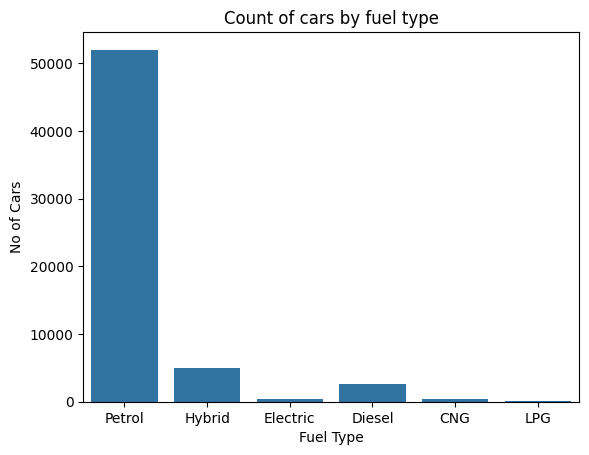

In [22]:
sns.countplot(data=df, x='Engine_type')
plt.xlabel("Fuel Type")
plt.ylabel("No of Cars")
plt.title("Count of cars by fuel type")
plt.show();

In [23]:
df = df[~(df['Engine_type']=='Electric')]

In [24]:
a = df['Transmission'].value_counts()

In [25]:
df['CC'].apply(lambda x: 1 if 'k' in x else 0 ).value_counts()

CC
0    60050
1       66
Name: count, dtype: int64

In [26]:
inds = df['CC'].apply(lambda x: None if x=='' else 1).dropna().index

df = df.loc[inds].reset_index().drop(columns = ['index'])

In [27]:
df['Km_Driven'].apply(lambda x: x if x==',' else '')

0         
1         
2         
3         
4         
        ..
60109     
60110     
60111     
60112     
60113     
Name: Km_Driven, Length: 60114, dtype: str

In [28]:
inds = df['CC'].apply(lambda x: None if 'k' in x else 1 ).dropna().index

df = df.loc[inds].reset_index().drop(columns=['index'])

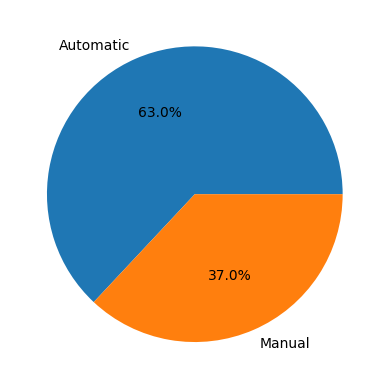

In [29]:
plt.pie(a.values, labels = a.index,  autopct='%1.1f%%');

In [30]:
df['Model'] = df['Model'].astype("int")
df['CC'] = df['CC'].astype("int")
df['Km_Driven'] = df['Km_Driven'].astype("int")

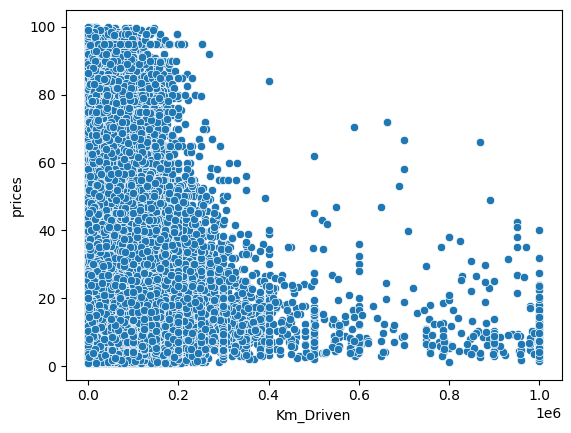

In [31]:
sns.scatterplot(x = 'Km_Driven', y = 'prices', data = df);

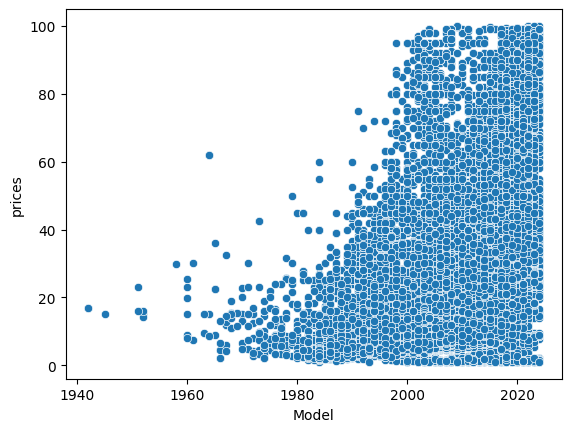

In [32]:
sns.scatterplot(x = 'Model', y = 'prices', data = df);

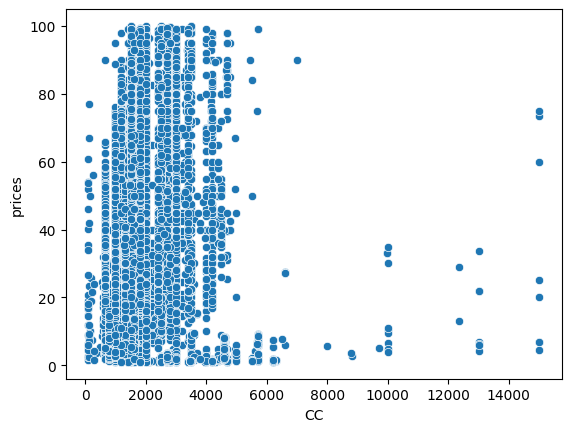

In [33]:
sns.scatterplot(x = 'CC', y = 'prices', data = df);

<Axes: xlabel='Km_Driven', ylabel='prices'>

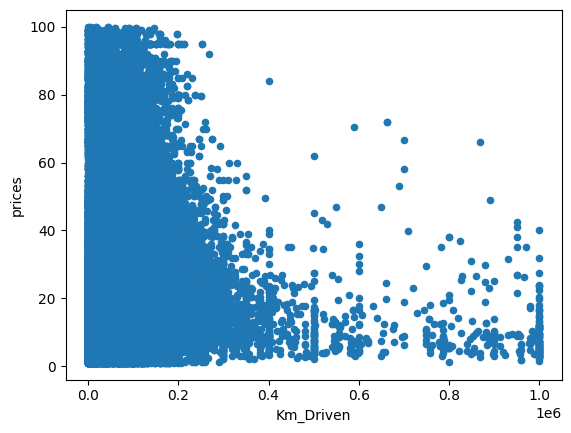

In [34]:
df.plot(kind = 'scatter', x = 'Km_Driven', y = 'prices')

<Axes: xlabel='Km_Driven', ylabel='prices'>

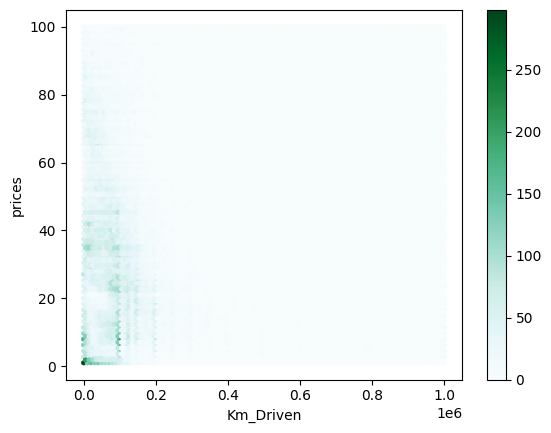

In [35]:
df.plot(kind = 'hexbin', x = 'Km_Driven', y = 'prices')

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60048 entries, 0 to 60047
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Model         60048 non-null  int64  
 1   CC            60048 non-null  int64  
 2   Engine_type   60048 non-null  str    
 3   Transmission  60048 non-null  str    
 4   Km_Driven     60048 non-null  int64  
 5   prices        59114 non-null  float64
 6   CarName       60048 non-null  object 
dtypes: float64(1), int64(3), object(1), str(2)
memory usage: 3.2+ MB


In [37]:
df.isnull().sum()

Model             0
CC                0
Engine_type       0
Transmission      0
Km_Driven         0
prices          934
CarName           0
dtype: int64

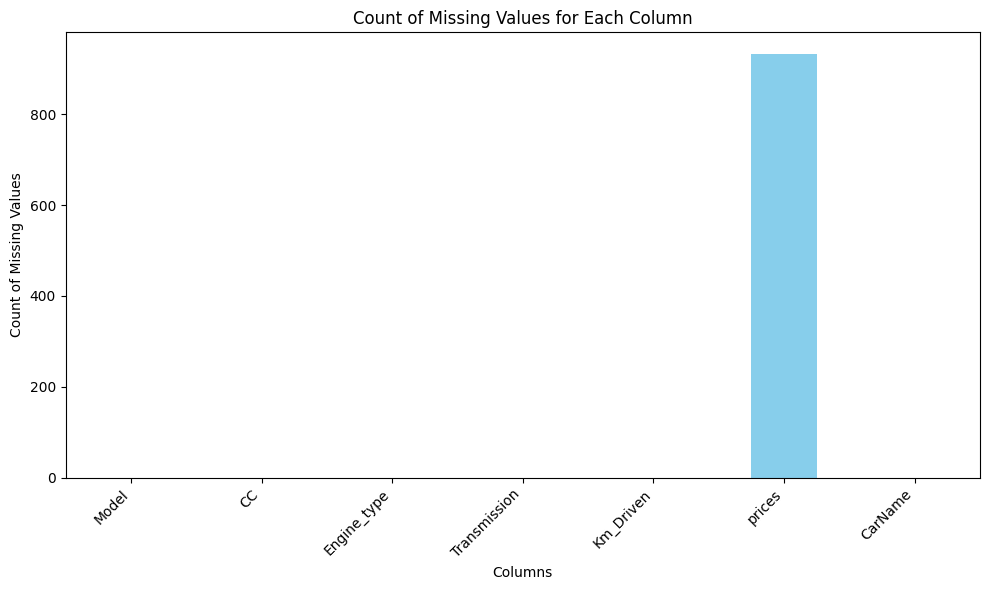

In [38]:
missing_values_count = df.isnull().sum()


plt.figure(figsize=(10, 6))
missing_values_count.plot(kind='bar', color='skyblue')
plt.title('Count of Missing Values for Each Column')
plt.xlabel('Columns')
plt.ylabel('Count of Missing Values')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show();

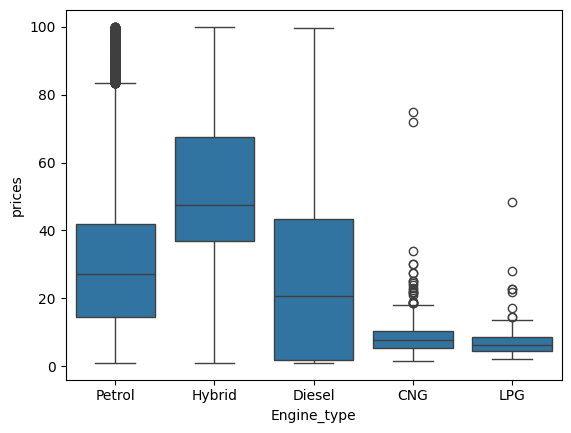

In [39]:
sns.boxplot(data=df, x = 'Engine_type', y = 'prices');

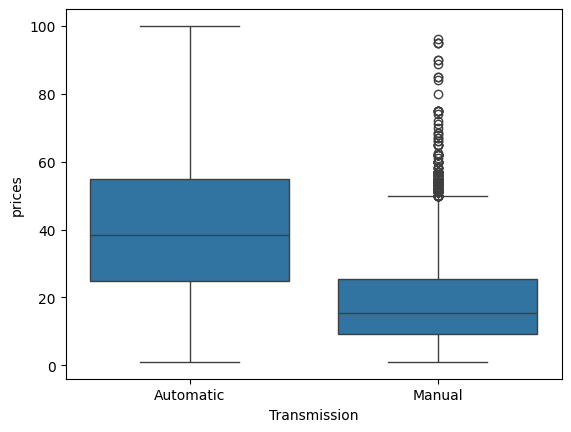

In [40]:
sns.boxplot(data=df, x = 'Transmission', y = 'prices');

In [41]:
df['CC'].nunique()

166

In [42]:
df.head()

,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,2019,1500,Petrol,Automatic,26755,72.50,Honda Vezel
1,2020,660,Hybrid,Automatic,9744,32.50,Suzuki Wagon R
2,2008,1500,Petrol,Automatic,85000,29.80,Toyota Corolla Axio
3,2018,1300,Petrol,Manual,40000,33.25,Toyota Corolla
4,2020,660,Petrol,Automatic,23300,35.75,Daihatsu Mira


<h1>Label Encoding</h1>

In [43]:
label_encoder = LabelEncoder()
cat_cols = df[['Transmission', 'Engine_type', 'CarName']]

label_encoders = {col: LabelEncoder().fit(df[col]) for col in cat_cols}

for col in cat_cols:
    df[col] = label_encoders[col].transform(df[col])

with open('label_encoders.pkl', 'wb') as f:
    pickle.dump(label_encoders, f)

In [44]:
df.head()

,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,2019,1500,4,0,26755,72.50,170
1,2020,660,2,0,9744,32.50,415
2,2008,1500,4,0,85000,29.80,442
3,2018,1300,4,1,40000,33.25,439
4,2020,660,4,0,23300,35.75,84


In [45]:
df.isnull().sum()

Model             0
CC                0
Engine_type       0
Transmission      0
Km_Driven         0
prices          934
CarName           0
dtype: int64

In [46]:
df['prices'] = df['prices'].fillna(round(df['prices'].mean(), 2))

In [47]:
df.head()

,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,2019,1500,4,0,26755,72.50,170
1,2020,660,2,0,9744,32.50,415
2,2008,1500,4,0,85000,29.80,442
3,2018,1300,4,1,40000,33.25,439
4,2020,660,4,0,23300,35.75,84


In [48]:
X = df.drop(columns = 'prices')
y = df['prices']

<h1>Mutual info Regression</h1>

In [49]:
mi_scores = mutual_info_regression(X, y)

mi_scores_df = pd.DataFrame({'Feature': X.columns, 'MI Score': mi_scores})

mi_scores_df_sorted = mi_scores_df.sort_values(by='MI Score', ascending=True)
mi_scores_df_sorted

,Feature,MI Score
2,Engine_type,0.100979
3,Transmission,0.250273
4,Km_Driven,0.291769
0,Model,0.474296
1,CC,0.630146
5,CarName,1.033106


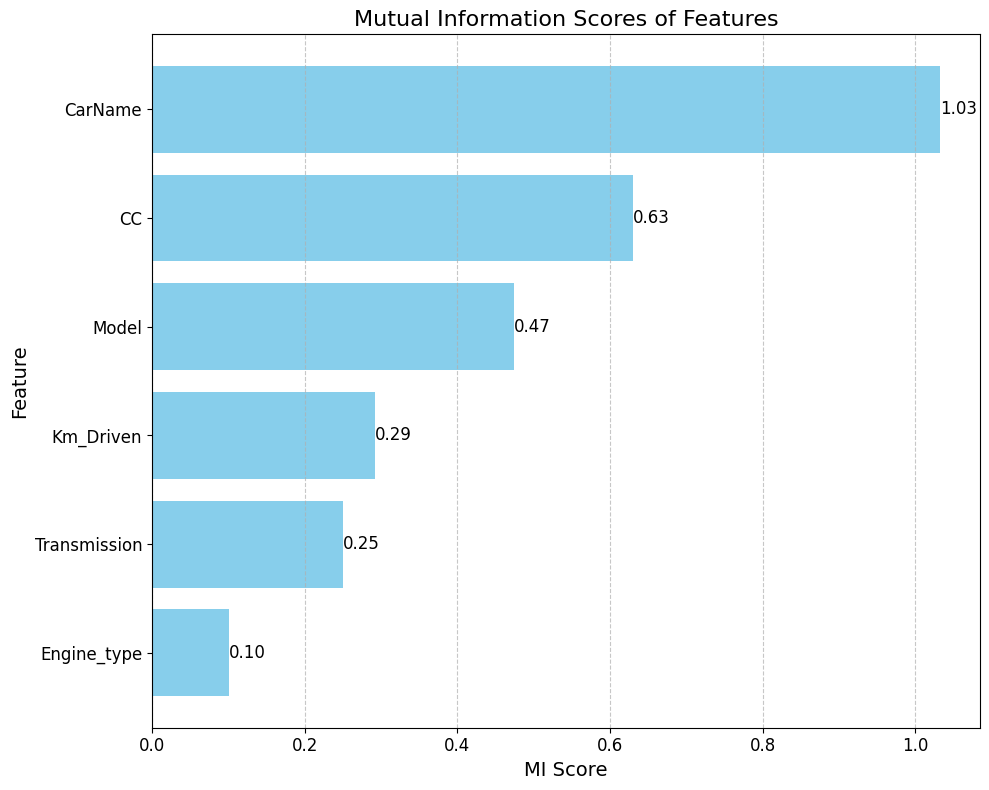

In [50]:

plt.figure(figsize=(10, 8))
bars = plt.barh(mi_scores_df_sorted['Feature'], mi_scores_df_sorted['MI Score'], color='skyblue')

plt.title('Mutual Information Scores of Features', fontsize=16)
plt.xlabel('MI Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)


for bar in bars:
    plt.text(bar.get_width(), bar.get_y() + bar.get_height()/2, f'{bar.get_width():.2f}', 
             va='center', ha='left', fontsize=12, color='black')


plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()


plt.show();

In [51]:
scaler = StandardScaler().fit(X[['Model', 'CC', 'Km_Driven']])


X[['Model', 'CC', 'Km_Driven']] = scaler.transform(X[['Model', 'CC', 'Km_Driven']])
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

In [52]:
X.head()

,Model,CC,Engine_type,Transmission,Km_Driven,CarName
0,0.656370,0.056413,4,0,-0.715505,170
1,0.771020,-1.035178,2,0,-0.912284,415
2,-0.604784,0.056413,4,0,-0.041743,442
3,0.541719,-0.203490,4,1,-0.562291,439
4,0.771020,-1.035178,4,0,-0.755472,84


When i kept test size 20% i got accuracy 79 but on 0.3 i got 85

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, test_size = 0.3)

In [54]:
X_train['Engine_type'].value_counts()

Engine_type
4    36435
2     3420
1     1834
0      306
3       38
Name: count, dtype: int64

<h1>RandomForestRegressor</h1>

In [55]:
forest = RandomForestRegressor(random_state=42)
forest.fit(X_train, y_train)
round(forest.score(X_test, y_test), 2) * 100

88.0

In [56]:
forest_pred = forest.predict(X_test)
forest_pred

array([24.82966667, 44.374     , 23.426     , ...,  2.7737    ,
       34.79513571, 13.06480119], shape=(18015,))

In [57]:
acc_train = forest.score(X_train, y_train)
acc_test = forest.score(X_test, y_test)

print("Training Accuracy:", round(acc_train, 4))
print("Test Accuracy:", round(acc_test, 4))

Training Accuracy: 0.9782
Test Accuracy: 0.8777


In [58]:
importances = forest.feature_importances_
importances

array([0.20634593, 0.2802093 , 0.03838685, 0.2365682 , 0.09308354,
       0.14540619])

In [59]:
indices = np.argsort(importances)[::-1]
indices

array([1, 3, 0, 5, 4, 2])

In [60]:
names = [X_train.columns[i] for i in indices]
names

['CC', 'Transmission', 'Model', 'CarName', 'Km_Driven', 'Engine_type']

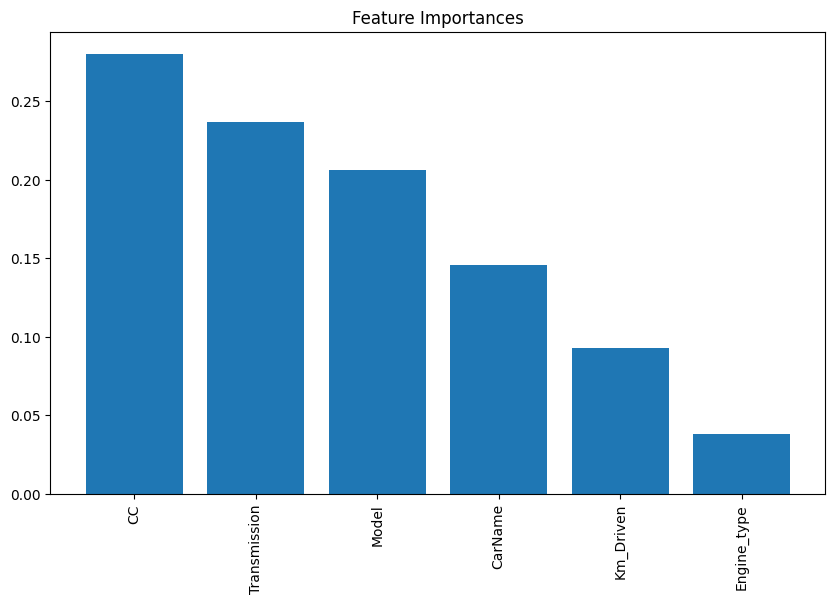

In [61]:
plt.figure(figsize=(10, 6))
plt.title("Feature Importances")
plt.bar(range(X_train.shape[1]), importances[indices])
plt.xticks(range(X_train.shape[1]), names, rotation=90)
plt.show()

<h1>GradientBoostingRegressor</h1>

In [62]:
clr2 = GradientBoostingRegressor()

In [63]:
params = {
    'n_estimators' : range(25, 200, 25),
    'max_depth' : range(10, 100, 10)
}

In [64]:
model_gredb = GridSearchCV(
    clr2,
    verbose = 1,
    cv = 5,
    n_jobs = -1,
    param_grid = params
)

In [65]:
model_gredb.fit(X_train, y_train)

Fitting 5 folds for each of 63 candidates, totalling 315 fits


KeyboardInterrupt: 

In [ ]:
gred_pred = model_gredb.predict(X_test)
gred_pred

In [ ]:
Mae_gred = mean_absolute_error(y_test, gred_pred)
print("Mean Absolute Error:" , Mae_gred)

In [ ]:
r23 = r2_score(y_test, gred_pred)
print('R-squared Score:', round(r23, 2))

In [ ]:
acc_train = model_gredb.score(X_train, y_train)
acc_test = model_gredb.score(X_test, y_test)

print("Training Accuracy:", round(acc_train, 4))
print("Test Accuracy:", round(acc_test, 4))

<h1>
    Cross Validation
</h1>

In [ ]:
my_pipeline = Pipeline(steps = [('model', RandomForestRegressor(random_state=42, n_estimators=50))])

In [ ]:
cv_acc_scores = cross_val_score(my_pipeline, X_train, y_train, cv = 5, n_jobs = -1)
print(cv_acc_scores.mean())

<h1>
    XGBRegressor
</h1>

In [ ]:
model_xgb = XGBRegressor(n_estimators = 1000, random_state = 42)

In [ ]:
model_xgb.fit(X_train, y_train, verbose = False, early_stopping_rounds = 5, eval_set = [(X_train, y_train)])

In [ ]:
xgb_pred = model_xgb.predict(X_test)
xgb_pred

In [ ]:
Mae_gred = mean_absolute_error(y_test, xgb_pred)
print("Mean Absolute Error:" , Mae_gred)

In [ ]:
r23 = r2_score(y_test, xgb_pred)
print('R-squared Score:', round(r23, 2))

In [ ]:
KM__Driven = int(input('Enter KM Driven: '))
CC__ = int(input('Enter CC: '))
Model__ = int(input('Enter Model: '))
Engine_type__ = input('Enter engine type: ')
car_name__ = input('Enter car name: ')
Transmission__ = input('Enter transmission: ')

new_data1 = {
    'Model': Model__,
    'CC': CC__,
    'Engine_type': Engine_type__,
    'Transmission': Transmission__,
    'Km_Driven': KM__Driven,
    'CarName': car_name__
    
}


new_data = pd.DataFrame(new_data1, index=[0])
new_data

In [ ]:
categorical_cols = ['Engine_type', 'Transmission', 'CarName']
for col in categorical_cols:
    le = label_encoders[col]
    if new_data[col][0] not in le.classes_:
        le.classes_ = np.append(le.classes_, new_data[col][0])
    new_data[col] = le.transform(new_data[col])

numerical_cols = ['Model', 'CC', 'Km_Driven']
new_data[numerical_cols] = scaler.transform(new_data[numerical_cols])
    
    
new_data = new_data[['Model', 'CC', 'Engine_type', 'Transmission', 'Km_Driven', 'CarName']]
    
    
prediction = forest.predict(new_data)

print(prediction)

<h1>Saving the model</h1>

In [ ]:
pickle.dump(forest, open('model_car_price_predict.pkl', 'wb'))

In [ ]:
with open("model_car_price_predict.pkl", 'rb') as f:
    model = pickle.load(f)

y_test_pred = model.predict(X_test)

y_test_pred = pd.Series(y_test_pred, index = X_test.index, name = 'bankrupt')
y_test_pred

In [ ]:
new_data['Model_Sc'] = scaler.fit_transform(new_data['Model'].values.reshape(-1, 1))
new_data['CC_Sc'] = scaler.fit_transform(new_data['CC'].values.reshape(-1, 1))
new_data['Km_Driven_Sc'] = scaler.fit_transform(new_data['Km_Driven'].values.reshape(-1, 1))

In [ ]:
new_data['Transmission_encoded'] = label_encoder.fit_transform(new_data['Transmission'])
new_data['Engine_type_encoded'] = label_encoder.fit_transform(new_data['Engine_Type'])
new_data['CarName_encoded'] = label_encoder.fit_transform(new_data['CarName'])

In [ ]:
prediction_on_new_data = model_tree.predict(new_data)
prediction_on_new_data

In [ ]:
param_distributions = {
    'n_estimators': [int(x) for x in np.linspace(start=100, stop=1000, num=10)],
    'max_features': ['auto', 'sqrt'],
    'max_depth': [int(x) for x in np.linspace(10, 110, num=11)] + [None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

In [ ]:
random_search.fit(X_train, y_train)
round(random_search.score(X_test, y_test), 2) * 100

In [ ]:
model_forest = RandomForestRegressor(random_state = 42)
random_search = RandomizedSearchCV(estimator=model_forest, param_distributions=param_distributions, 
                                   n_iter=100, cv=3, verbose=2, random_state=42, n_jobs=-1)

In [ ]:
#round(grid_search.score(X_test, y_test), 2) * 100

In [ ]:
#grid_search = GridSearchCV(estimator=forest, param_grid = param_grid,  n_jobs = -1, cv = 5)
#grid_search.fit(X_train, y_train) 

In [ ]:
#param_grid = {
 #   'n_estimators': [100, 200, 300], 
  #  'max_depth': [5, 10, 15],          
   # 'min_samples_split': [2, 5, 10],   
    #'min_samples_leaf': [1, 2, 4]       
#}

#forest = RandomForestRegressor(random_state=42)